# 01 — Data Understanding: Synthetic Longitudinal Customer Churn Panel

**What this dataset represents:** a synthetic (artificially generated, not real)
customer-month panel for a subscription/telecom-style business, covering
**6,000 customers** from **January 2021 to December 2025**. Each row is one
customer's state in one month they were active. A customer contributes
multiple rows over time and stops appearing in the panel the month after
they churn.

**Why we are inspecting it:** before building any cleaning pipeline or model,
we need to confirm the raw data actually behaves the way it's supposed to —
right shape, right date range, right customer structure, and no obvious
red flags — and get a first honest look at what the data shows.

**What this notebook answers:**
- Does the raw file match the expected structure (6,000 customers, ~253K rows, Jan 2021–Dec 2025)?
- How is the panel structured at the customer level (rows per customer, timelines, churn behavior)?
- What does the raw churn signal actually look like (event rate vs. customer-level rate)?
- What do cohorts, feature distributions, and churn-vs-variable patterns look like?
- What data quality issues exist that the cleaning pipeline will need to handle?
- What leakage risks exist for the eventual ML model?

**Important:** this notebook is exploratory only. It does **not** modify the
raw CSV, clean data, engineer features, train models, or write to a database.


## 2. Load the Data

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# Project-root-relative, Windows/Linux/Mac safe path (no hard-coded absolute paths)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "customer_month_raw.csv"
print("Reading from:", RAW_PATH)
assert RAW_PATH.exists(), f"Raw file not found at {RAW_PATH} — run this notebook from the project root."


Reading from: /home/claude/churn_project/data/raw/customer_month_raw.csv


In [2]:
df = pd.read_csv(RAW_PATH, parse_dates=["activity_month", "signup_month"])
print("Shape:", df.shape)
df.head()


Shape: (253811, 19)


,customer_id,activity_month,tenure_months,region,customer_segment,age,contract_type,payment_method,plan,monthly_charges,usage_gb,num_addon_services,support_calls_this_month,is_active,churn_this_month,signup_month,cohort_year,cohort_month,churn_hazard_latent
0,CUST-100968,2022-01-01,34,North,Consumer,51.0,One year,Bank transfer (auto),Basic,38.40,19.4,1,0,1,0,2019-03-01,2019,3,0.00867
1,CUST-102013,2021-01-01,30,South,Consumer,18.0,Month-to-month,Bank transfer (auto),Standard,55.33,52.9,0,0,1,0,2018-07-01,2018,7,0.02416
2,CUST-102617,2022-06-01,17,North,Consumer,24.0,Month-to-month,Bank transfer (auto),Basic,31.43,19.4,0,0,1,0,2021-01-01,2021,1,0.01402
3,CUST-102185,2025-09-01,105,South,Consumer,33.0,Two year,Electronic check,Basic,56.16,20.2,1,1,1,0,2016-12-01,2016,12,0.02634
4,CUST-103486,2022-09-01,33,North,SMB,46.0,Month-to-month,Electronic check,Basic,28.00,20.8,0,0,1,0,2019-12-01,2019,12,0.01991


In [3]:
print("Column names:")
print(list(df.columns))


Column names:
['customer_id', 'activity_month', 'tenure_months', 'region', 'customer_segment', 'age', 'contract_type', 'payment_method', 'plan', 'monthly_charges', 'usage_gb', 'num_addon_services', 'support_calls_this_month', 'is_active', 'churn_this_month', 'signup_month', 'cohort_year', 'cohort_month', 'churn_hazard_latent']


In [4]:
df.dtypes


customer_id                            str
activity_month              datetime64[us]
tenure_months                        int64
region                                 str
customer_segment                       str
age                                float64
contract_type                          str
payment_method                         str
plan                                   str
monthly_charges                    float64
usage_gb                           float64
num_addon_services                   int64
support_calls_this_month             int64
is_active                            int64
churn_this_month                     int64
signup_month                datetime64[us]
cohort_year                          int64
cohort_month                         int64
churn_hazard_latent                float64
dtype: object

## 3. Data Dictionary

This is a working reference for the raw file as delivered by the synthetic
data generator — **before** any cleaning. Column meanings may shift slightly
once the cleaning pipeline adds derived fields; this table describes what
exists in `customer_month_raw.csv` today.


In [5]:
data_dictionary = pd.DataFrame([
    ("customer_id", "Unique customer identifier", "string", "Yes (as ID/grouping key, not a feature)", "None"),
    ("activity_month", "The month this row describes (first-of-month)", "datetime", "Indirectly (derive period features)", "Raw month value itself should not be fed directly as a naive numeric feature"),
    ("tenure_months", "Months since signup, as of this row's month", "int", "Yes", "Legitimate, same-row feature"),
    ("region", "Customer region (North/South/East/West)", "category", "Yes", "Check for inconsistent category text before modelling"),
    ("customer_segment", "Consumer / SMB / Enterprise", "category", "Yes", "None"),
    ("age", "Customer age", "int/float", "Yes, after validation", "Contains invalid values (see Section 10)"),
    ("contract_type", "Month-to-month / One year / Two year, can change over time", "category", "Yes", "Reflects state AS OF this row's month — legitimate"),
    ("payment_method", "Payment method, can change over time", "category", "Yes, after validation", "Contains missing values"),
    ("plan", "Basic / Standard / Premium, can change (rare)", "category", "Yes", "None"),
    ("monthly_charges", "This month's bill", "float", "Yes", "Contains injected outliers (see Section 10)"),
    ("usage_gb", "This month's usage/engagement proxy", "float", "Yes", "Contains missing values"),
    ("num_addon_services", "Count of add-on services this month", "int", "Yes", "None"),
    ("support_calls_this_month", "Support/complaint calls in this specific month", "int", "Yes", "None"),
    ("is_active", "Always 1 in this raw extract (rows only exist while active)", "int", "No — constant, no predictive value", "Not a real signal; rows simply stop after churn"),
    ("churn_this_month", "1 only in the exact month a customer churns; 0 otherwise", "int (0/1)", "TARGET VARIABLE", "This is what we are trying to predict — never use as a feature"),
    ("signup_month", "First-of-month signup date", "datetime", "Indirectly (derive cohort features)", "Legitimate as a source for cohort_year/cohort_month, which are already provided"),
    ("cohort_year", "Year of signup", "int", "Yes, for cohort-level analysis/features", "None"),
    ("cohort_month", "Month of signup (1-12)", "int", "Yes, for cohort-level analysis/features", "None"),
    ("churn_hazard_latent", "The EXACT probability used internally by the generator to draw that row's churn outcome", "float", "NO — DO NOT USE", "SYNTHETIC-GENERATION ARTIFACT. Directly encodes the answer. Using this would leak the target and make any model meaningless. Must be dropped before modelling."),
], columns=["column", "meaning", "type", "use_in_modeling", "notes_leakage_risk"])

pd.set_option("display.max_colwidth", 100)
data_dictionary


,column,meaning,type,use_in_modeling,notes_leakage_risk
0,customer_id,Unique customer identifier,string,"Yes (as ID/grouping key, not a feature)",None
1,activity_month,The month this row describes (first-of-month),datetime,Indirectly (derive period features),Raw month value itself should not be fed directly as a naive numeric feature
2,tenure_months,"Months since signup, as of this row's month",int,Yes,"Legitimate, same-row feature"
3,region,Customer region (North/South/East/West),category,Yes,Check for inconsistent category text before modelling
4,customer_segment,Consumer / SMB / Enterprise,category,Yes,None
5,age,Customer age,int/float,"Yes, after validation",Contains invalid values (see Section 10)
6,contract_type,"Month-to-month / One year / Two year, can change over time",category,Yes,Reflects state AS OF this row's month — legitimate
7,payment_method,"Payment method, can change over time",category,"Yes, after validation",Contains missing values
8,plan,"Basic / Standard / Premium, can change (rare)",category,Yes,None
9,monthly_charges,This month's bill,float,Yes,Contains injected outliers (see Section 10)


**Columns needing special attention:**

- **`churn_this_month`** — the target. In this raw file it is only 1 in a
  customer's *final* row (the month they churned); every other row is 0.
- **`churn_hazard_latent`** — a generator-internal value, not a real-world
  measurement. It must never be used as a model feature — it was the
  probability used to *decide* the churn outcome, so using it is equivalent
  to giving the model the answer.
- **`activity_month`** — describes *when* the row is, not a property of the
  customer that predicts anything on its own; needs to be handled carefully
  (e.g. via derived calendar/seasonal features) rather than used raw.
- **`signup_month`** — a legitimate source for cohort features, but should
  not be combined with `activity_month` in a way that leaks the customer's
  eventual total tenure into an earlier row.
- **`tenure_months`** — legitimate, same-row-in-time feature.
- **`is_active`** — constant (always 1) in this extract; carries no
  information since rows simply stop existing after churn.


## 4. Customer-Level Structure

Checking that the panel is actually structured the way the project assumes:
multiple rows per customer, and rows stopping after churn.


In [6]:
n_unique_customers = df["customer_id"].nunique()
rows_per_customer = df.groupby("customer_id").size()

print(f"Unique customers: {n_unique_customers}")
print(f"Total rows: {len(df)}")
print()
print("Rows (months observed) per customer:")
print(rows_per_customer.describe())


Unique customers: 6000
Total rows: 253811

Rows (months observed) per customer:
count    6000.000000
mean       42.301833
std        21.993628
min         1.000000
25%        20.000000
50%        60.000000
75%        60.000000
max        65.000000
dtype: float64


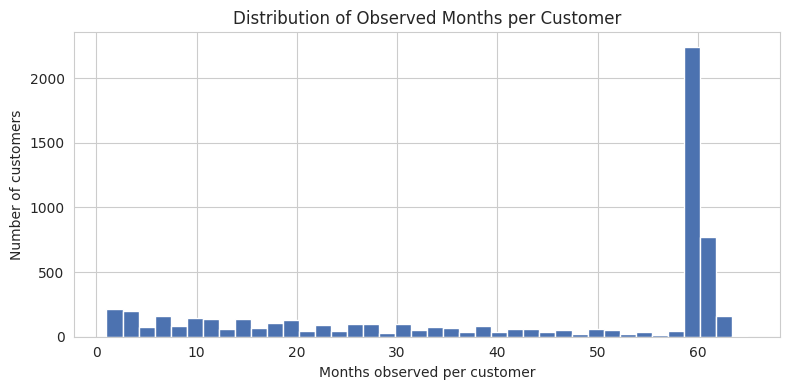

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
rows_per_customer.plot(kind="hist", bins=40, ax=ax, color="#4C72B0")
ax.set_xlabel("Months observed per customer")
ax.set_ylabel("Number of customers")
ax.set_title("Distribution of Observed Months per Customer")
plt.tight_layout()
plt.show()


In [8]:
# Check: does each customer's activity_month sequence look continuous (no gaps),
# and does the customer stop appearing after their churn row?
# Note: duplicate rows (a known, intentionally injected data quality issue — see Section 10)
# are de-duplicated by month here first, so this check isolates TRUE gaps in the monthly
# sequence from the separate, already-documented duplicate-row issue.
def check_customer_continuity(cid, frame):
    sub = frame[frame["customer_id"] == cid].sort_values("activity_month")
    months = sub["activity_month"].dt.to_period("M").drop_duplicates()
    expected = pd.period_range(months.min(), months.max(), freq="M")
    is_continuous = list(months.sort_values()) == list(expected)
    churn_rows = sub[sub["churn_this_month"] == 1]
    stops_after_churn = True
    if len(churn_rows) > 0:
        churn_month = churn_rows["activity_month"].iloc[0]
        stops_after_churn = (sub["activity_month"] <= churn_month).all()
    return is_continuous, stops_after_churn, len(sub)

sample_ids = df["customer_id"].drop_duplicates().sample(200, random_state=1)
results = [check_customer_continuity(cid, df) for cid in sample_ids]
continuity_ok = sum(r[0] for r in results)
stop_after_churn_ok = sum(r[1] for r in results)
print(f"Sampled 200 customers:")
print(f"  Continuous monthly sequence, gaps checked after de-duplicating months (dup rows are a separate, documented issue): {continuity_ok}/200")
print(f"  Rows stop at/before churn month (no post-churn rows): {stop_after_churn_ok}/200")


Sampled 200 customers:
  Continuous monthly sequence, gaps checked after de-duplicating months (dup rows are a separate, documented issue): 200/200
  Rows stop at/before churn month (no post-churn rows): 200/200


In [9]:
# Show a few example customer timelines: one who churned, one still active
churned_example = df[df["churn_this_month"] == 1]["customer_id"].iloc[0]
active_example = df[~df["customer_id"].isin(df[df["churn_this_month"] == 1]["customer_id"])]["customer_id"].iloc[0]

cols_to_show = ["activity_month", "tenure_months", "contract_type", "payment_method",
                 "monthly_charges", "usage_gb", "support_calls_this_month", "churn_this_month"]

print("Example CHURNED customer timeline:", churned_example)
display(df[df["customer_id"] == churned_example][cols_to_show].sort_values("activity_month"))

print("\nExample STILL-ACTIVE customer timeline (last 6 rows):", active_example)
display(df[df["customer_id"] == active_example][cols_to_show].sort_values("activity_month").tail(6))


Example CHURNED customer timeline: CUST-103413


,activity_month,tenure_months,contract_type,payment_method,monthly_charges,usage_gb,support_calls_this_month,churn_this_month
125222,2021-01-01,57,Two year,Electronic check,70.94,26.6,0,0
93666,2021-02-01,58,Two year,Electronic check,63.69,35.3,0,0
95340,2021-03-01,59,Two year,Electronic check,67.24,44.2,1,0
113948,2021-04-01,60,Two year,Electronic check,68.24,41.7,3,0
161,2021-05-01,61,Two year,Electronic check,65.66,48.3,1,1



Example STILL-ACTIVE customer timeline (last 6 rows): CUST-102013


,activity_month,tenure_months,contract_type,payment_method,monthly_charges,usage_gb,support_calls_this_month,churn_this_month
116338,2025-07-01,84,One year,Bank transfer (auto),88.29,NaN,0,0
248411,2025-08-01,85,One year,Bank transfer (auto),84.06,61.5,0,0
91302,2025-09-01,86,One year,Bank transfer (auto),83.97,58.4,0,0
185841,2025-10-01,87,One year,NaN,81.97,62.7,0,0
54728,2025-11-01,88,One year,Bank transfer (auto),93.69,73.8,0,0
242079,2025-12-01,89,One year,Bank transfer (auto),87.07,72.5,1,0


## 5. Time Coverage

In [10]:
print("Min activity_month:", df["activity_month"].min())
print("Max activity_month:", df["activity_month"].max())


Min activity_month: 2021-01-01 00:00:00
Max activity_month: 2025-12-01 00:00:00


In [11]:
expected_months = pd.period_range("2021-01", "2025-12", freq="M")
actual_months = df["activity_month"].dt.to_period("M").unique()
missing_months = sorted(set(expected_months) - set(actual_months))
print(f"Expected months: {len(expected_months)} (Jan 2021 - Dec 2025)")
print(f"Months actually present: {len(actual_months)}")
print(f"Missing months: {missing_months if missing_months else 'None — full coverage'}")


Expected months: 60 (Jan 2021 - Dec 2025)
Months actually present: 60
Missing months: None — full coverage


Observations by year:
activity_month
2021    59206
2022    53240
2023    49538
2024    46787
2025    45040
Name: count, dtype: int64


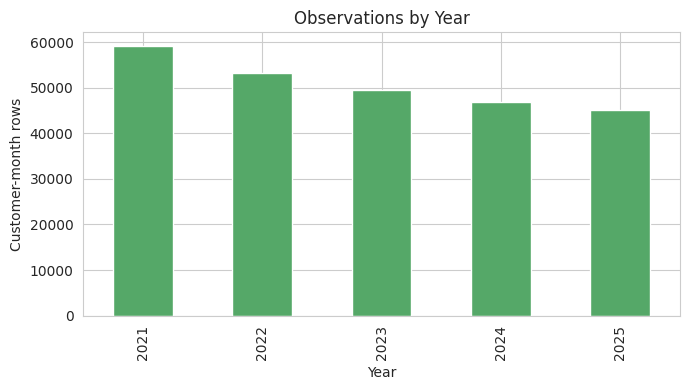

In [12]:
by_year = df["activity_month"].dt.year.value_counts().sort_index()
print("Observations by year:")
print(by_year)

fig, ax = plt.subplots(figsize=(7, 4))
by_year.plot(kind="bar", ax=ax, color="#55A868")
ax.set_xlabel("Year"); ax.set_ylabel("Customer-month rows")
ax.set_title("Observations by Year")
plt.tight_layout()
plt.show()


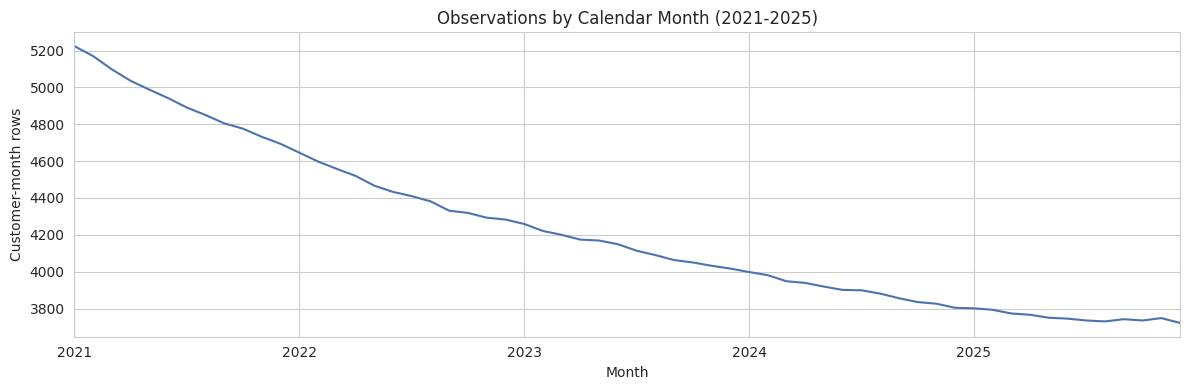

In [13]:
by_month = df.groupby(df["activity_month"].dt.to_period("M")).size()
fig, ax = plt.subplots(figsize=(12, 4))
by_month.plot(ax=ax, color="#4C72B0")
ax.set_xlabel("Month"); ax.set_ylabel("Customer-month rows")
ax.set_title("Observations by Calendar Month (2021-2025)")
plt.tight_layout()
plt.show()


The active-row count trends downward over the panel's later months — this
is expected and mechanical, not a data quality problem: newer cohorts have
had less time to accumulate months, and the panel includes ongoing attrition.
This shape should be interpreted alongside cohort analysis (Section 7), not
read as a standalone anomaly.


## 6. Churn Analysis

**Important distinction used throughout this section:**
- **Monthly churn-event rate** = `churn_this_month` sum ÷ total customer-month
  rows. This answers "in a given month, what fraction of *active customer-months*
  end in churn?"
- **Percentage of unique customers who ever churned** = a completely different
  question — "of the 6,000 customers, what fraction churned at *any* point
  during the window?"

These are not interchangeable, and the 38.7%-style figure refers only to the
second one — it is **not** a monthly churn rate.


In [14]:
total_churn_events = int(df["churn_this_month"].sum())
total_rows = len(df)
monthly_churn_event_rate = 100 * total_churn_events / total_rows

ever_churned = df.groupby("customer_id")["churn_this_month"].max()
pct_customers_ever_churned = 100 * ever_churned.mean()
n_customers_ever_churned = int(ever_churned.sum())

print(f"Total churn events (rows where churn_this_month=1): {total_churn_events}")
print(f"Total customer-month rows: {total_rows}")
print(f"Monthly churn-event rate: {monthly_churn_event_rate:.3f}%  <-- rate PER MONTH, on a customer-month basis")
print()
print(f"Unique customers who ever churned in the window: {n_customers_ever_churned} of {df['customer_id'].nunique()}")
print(f"Percentage of customers who ever churned: {pct_customers_ever_churned:.2f}%  <-- a CUSTOMER-LEVEL figure, NOT a monthly rate")


Total churn events (rows where churn_this_month=1): 2338
Total customer-month rows: 253811
Monthly churn-event rate: 0.921%  <-- rate PER MONTH, on a customer-month basis

Unique customers who ever churned in the window: 2323 of 6000
Percentage of customers who ever churned: 38.72%  <-- a CUSTOMER-LEVEL figure, NOT a monthly rate


In [15]:
churn_by_year = df.groupby(df["activity_month"].dt.year)["churn_this_month"].agg(
    churn_events="sum", total_rows="count"
)
churn_by_year["monthly_churn_event_rate_pct"] = (100 * churn_by_year["churn_events"] / churn_by_year["total_rows"]).round(3)
churn_by_year


,churn_events,total_rows,monthly_churn_event_rate_pct
activity_month,,,
2021,756,59206,1.277
2022,552,53240,1.037
2023,434,49538,0.876
2024,345,46787,0.737
2025,251,45040,0.557


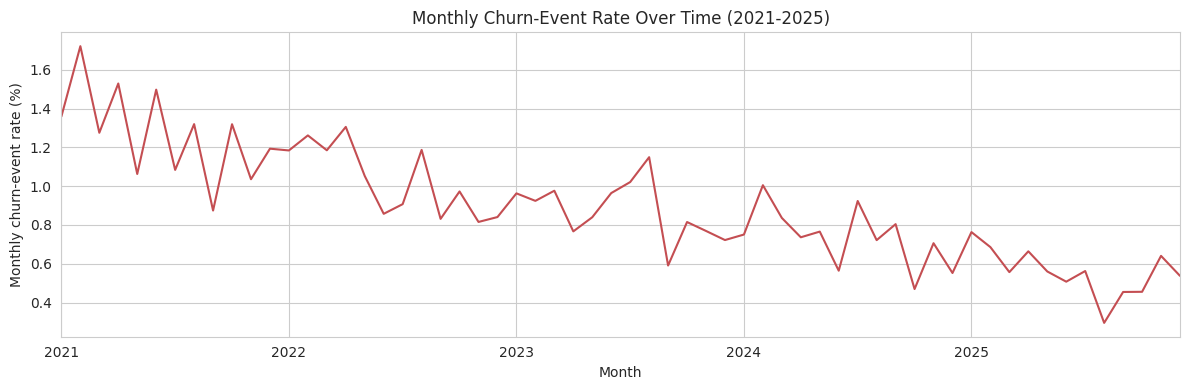

In [16]:
monthly_churn_trend = df.groupby(df["activity_month"].dt.to_period("M")).apply(
    lambda g: 100 * g["churn_this_month"].sum() / len(g), include_groups=False
)

fig, ax = plt.subplots(figsize=(12, 4))
monthly_churn_trend.plot(ax=ax, color="#C44E52")
ax.set_xlabel("Month"); ax.set_ylabel("Monthly churn-event rate (%)")
ax.set_title("Monthly Churn-Event Rate Over Time (2021-2025)")
plt.tight_layout()
plt.show()


## 7. Customer / Cohort Analysis

**Note on recent cohorts:** cohorts acquired close to the end of the
observation window (notably 2025, and late-2024) have not had as much
calendar time to reach longer tenure milestones as earlier cohorts. Any
apparent drop-off in their later-month retention may reflect this
**right-censoring** (not yet observed) rather than a real increase in churn.
These recent cohorts should not be interpreted the same way as fully-observed
older cohorts (2021-2023).


In [17]:
cohort_sizes = (
    df[df["tenure_months"] == 0]
    .groupby("cohort_year")["customer_id"]
    .nunique()
    .rename("customers_acquired")
)
cohort_sizes


cohort_year
2021    180
2022    155
2023    174
2024    148
2025    162
Name: customers_acquired, dtype: int64

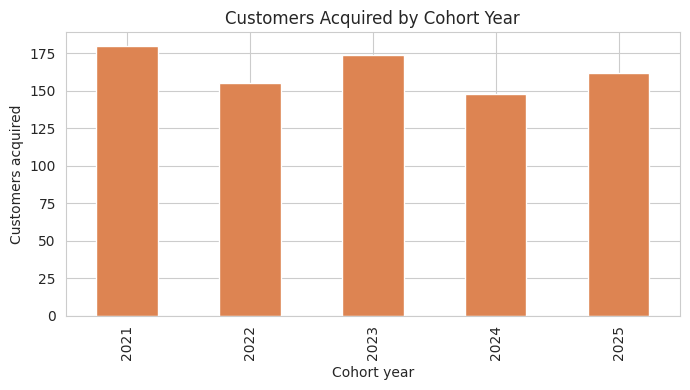

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
cohort_sizes.plot(kind="bar", ax=ax, color="#DD8452")
ax.set_xlabel("Cohort year"); ax.set_ylabel("Customers acquired")
ax.set_title("Customers Acquired by Cohort Year")
plt.tight_layout()
plt.show()


In [19]:
# Churn behavior by cohort year: what fraction of each cohort has churned so far
cohort_map = df[df["tenure_months"] == 0][["customer_id", "cohort_year"]]
merged = df.merge(cohort_map, on="customer_id", suffixes=("", "_c"))
cohort_churn = merged.groupby("cohort_year")["churn_this_month"].max().groupby(merged.groupby("cohort_year")["cohort_year"].first()).mean()

cohort_ever_churn = (
    merged.groupby(["cohort_year", "customer_id"])["churn_this_month"].max()
    .groupby("cohort_year").mean() * 100
).round(2)
cohort_ever_churn.rename("pct_of_cohort_churned_so_far")


cohort_year
2021    48.89
2022    42.58
2023    33.91
2024    22.97
2025     9.88
Name: pct_of_cohort_churned_so_far, dtype: float64

The cohort-level "percent churned so far" figure above is expected to look
*higher* for older cohorts (2021-2022) and *lower* for newer cohorts
(2024-2025) even under identical underlying churn behavior — older cohorts
have simply had more months of exposure in which to churn. This is the same
right-censoring effect noted above, and should not be read as "older cohorts
churn more."


## 8. Feature Distributions

### Numerical variables

In [20]:
numeric_cols = ["age", "tenure_months", "monthly_charges", "usage_gb",
                "num_addon_services", "support_calls_this_month"]
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
age,249999.0,42.063564,13.271706,0.00,33.00,42.00,51.00,85.000000
tenure_months,253811.0,54.842402,26.159131,0.00,36.00,55.00,74.00,119.000000
monthly_charges,253811.0,74.799740,33.780478,23.85,45.74,68.89,98.07,755.115193
usage_gb,250771.0,57.103817,35.754253,2.90,21.70,53.30,80.50,232.900000
num_addon_services,253811.0,1.143615,1.173375,0.00,0.00,1.00,2.00,5.000000
support_calls_this_month,253811.0,0.302509,0.553199,0.00,0.00,0.00,1.00,5.000000


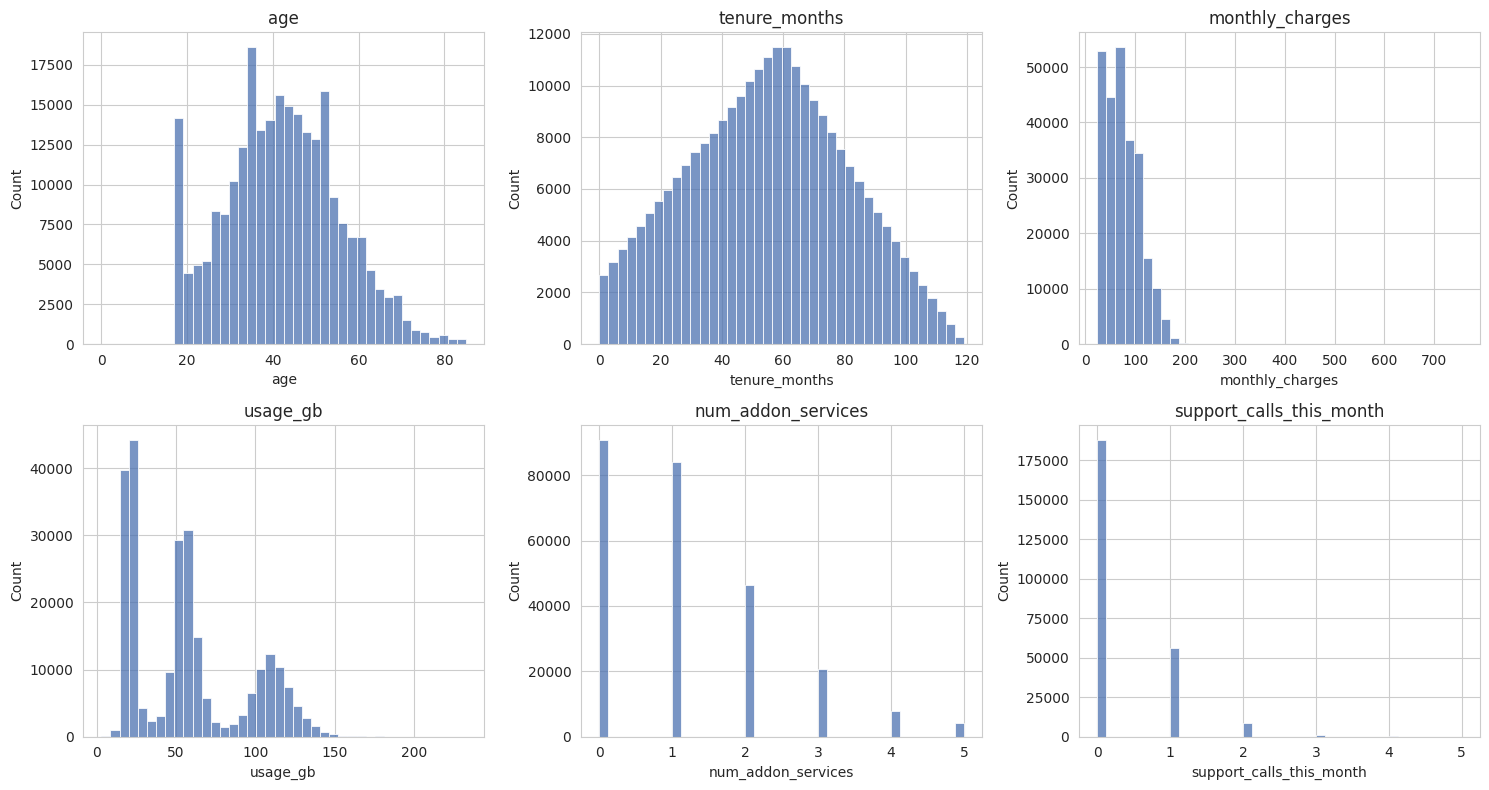

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout()
plt.show()


### Categorical variables

In [22]:
categorical_cols = ["region", "customer_segment", "contract_type", "payment_method", "plan"]
for col in categorical_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()


--- region ---
region
North     72726
East      69479
South     55641
West      54853
south       434
north       349
NORTH       329
Name: count, dtype: int64

--- customer_segment ---
customer_segment
Consumer      174264
SMB            61911
Enterprise     17636
Name: count, dtype: int64

--- contract_type ---
contract_type
One year          91843
Two year          87572
Month-to-month    74396
Name: count, dtype: int64

--- payment_method ---
payment_method
Credit card (auto)      80820
Bank transfer (auto)    76930
Electronic check        58625
Mailed check            35406
NaN                      2030
Name: count, dtype: int64

--- plan ---
plan
Standard    95112
Basic       93960
Premium     64739
Name: count, dtype: int64



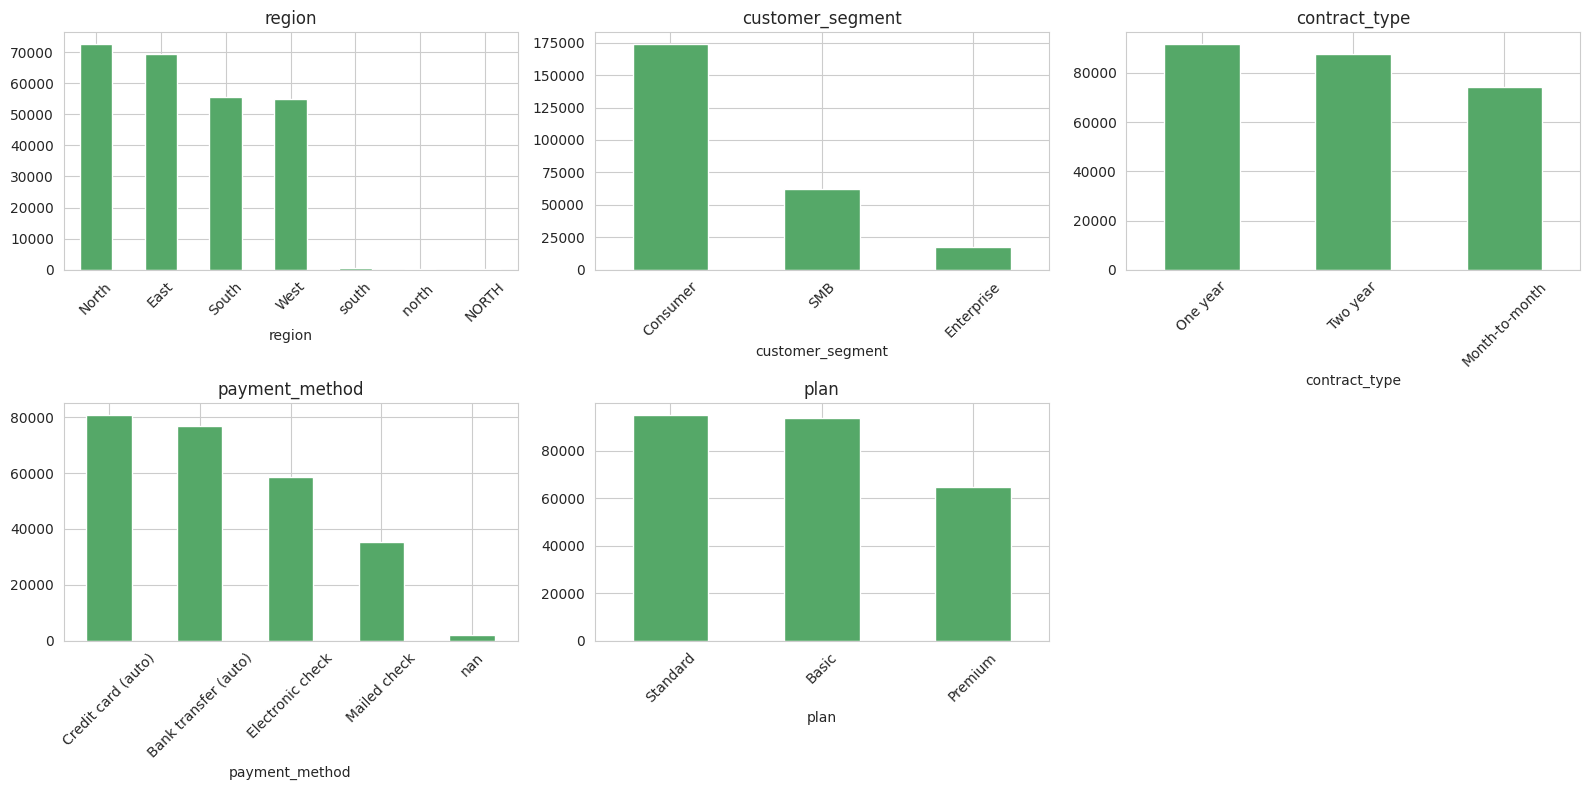

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, categorical_cols):
    df[col].value_counts(dropna=False).plot(kind="bar", ax=ax, color="#55A868")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


## 9. Churn vs. Business Variables

Churn-event rate (customer-month basis) broken down by key variables. Note:
these are observed associations in the data, not causal claims.


In [24]:
def churn_rate_by(col):
    out = df.groupby(col).apply(
        lambda g: 100 * g["churn_this_month"].sum() / len(g), include_groups=False
    ).sort_values(ascending=False)
    return out.rename("monthly_churn_event_rate_pct")

for col in ["contract_type", "payment_method", "plan", "customer_segment", "region"]:
    print(f"--- Monthly churn-event rate by {col} ---")
    print(churn_rate_by(col).round(3))
    print()


--- Monthly churn-event rate by contract_type ---
contract_type
Month-to-month    1.766
One year          0.821
Two year          0.308
Name: monthly_churn_event_rate_pct, dtype: float64

--- Monthly churn-event rate by payment_method ---
payment_method
Electronic check        1.508
Mailed check            1.135
Credit card (auto)      0.662
Bank transfer (auto)    0.646
Name: monthly_churn_event_rate_pct, dtype: float64

--- Monthly churn-event rate by plan ---


plan
Basic       1.230
Standard    0.878
Premium     0.536
Name: monthly_churn_event_rate_pct, dtype: float64

--- Monthly churn-event rate by customer_segment ---
customer_segment
SMB           0.961
Consumer      0.927
Enterprise    0.726
Name: monthly_churn_event_rate_pct, dtype: float64

--- Monthly churn-event rate by region ---
region
South     1.183
south     1.152
West      0.946
East      0.836
North     0.788
NORTH     0.304
north     0.287
Name: monthly_churn_event_rate_pct, dtype: float64



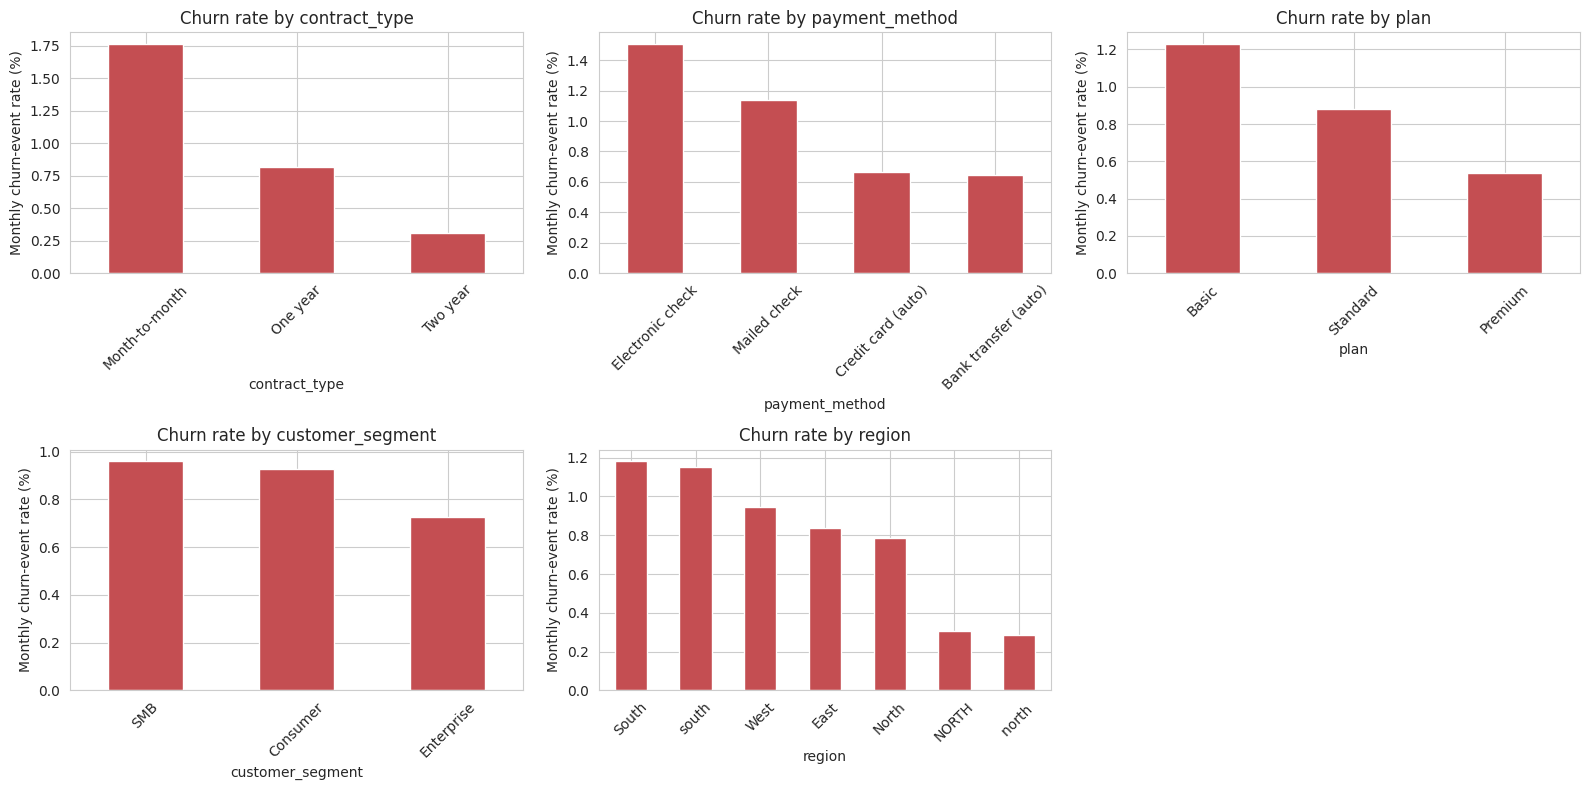

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["contract_type", "payment_method", "plan", "customer_segment", "region"]):
    churn_rate_by(col).plot(kind="bar", ax=ax, color="#C44E52")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Monthly churn-event rate (%)")
    ax.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


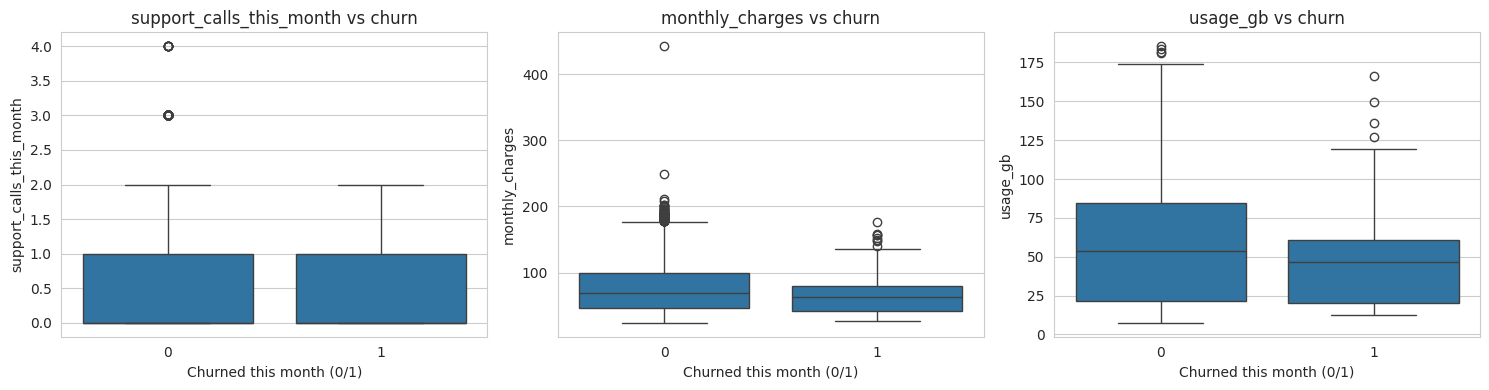

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["support_calls_this_month", "monthly_charges", "usage_gb"]):
    sns.boxplot(data=df.sample(min(30000, len(df)), random_state=1), x="churn_this_month", y=col, ax=ax)
    ax.set_xlabel("Churned this month (0/1)")
    ax.set_title(f"{col} vs churn")
plt.tight_layout()
plt.show()


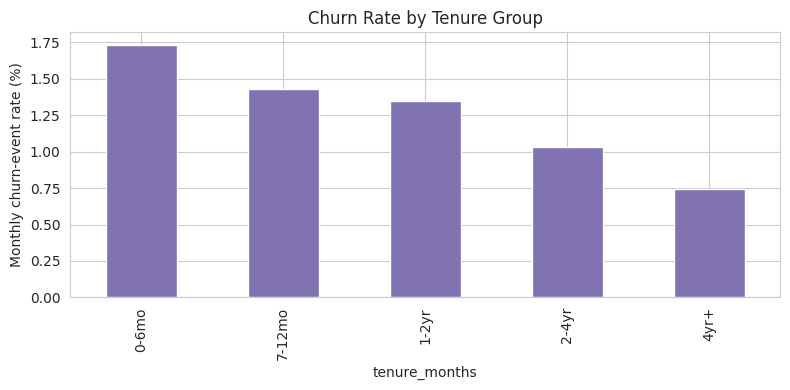

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
tenure_bins = pd.cut(df["tenure_months"], bins=[-1, 6, 12, 24, 48, 999],
                      labels=["0-6mo", "7-12mo", "1-2yr", "2-4yr", "4yr+"])
tenure_churn = df.groupby(tenure_bins, observed=True).apply(
    lambda g: 100 * g["churn_this_month"].sum() / len(g), include_groups=False
)
tenure_churn.plot(kind="bar", ax=ax, color="#8172B2")
ax.set_ylabel("Monthly churn-event rate (%)")
ax.set_title("Churn Rate by Tenure Group")
plt.tight_layout()
plt.show()


**Observed associations only** — the patterns above describe what is
present in the data (e.g. "higher churn-event rates were observed among
month-to-month customers"), not a claim that any one variable *causes*
churn. Causal/predictive modelling is out of scope for this notebook.


## 10. Data Quality Checks

This section only **identifies and documents** issues. Nothing is fixed here
— that is the job of the cleaning pipeline (`src/clean_data.py`).


In [28]:
print("=== Missing values ===")
missing = df.isna().sum()
print(missing[missing > 0])


=== Missing values ===
age               3812
payment_method    2030
usage_gb          3040
dtype: int64


In [29]:
print("=== Exact duplicate rows ===")
print(f"Fully duplicated rows: {df.duplicated().sum()}")

print()
print("=== Duplicate customer-month combinations ===")
print(f"Duplicate (customer_id, activity_month) pairs: {df.duplicated(subset=['customer_id', 'activity_month']).sum()}")


=== Exact duplicate rows ===


Fully duplicated rows: 1513

=== Duplicate customer-month combinations ===
Duplicate (customer_id, activity_month) pairs: 1513


In [30]:
print("=== Invalid ages ===")
invalid_age = df[(df["age"] <= 0) | (df["age"] > 100)]
print(f"Rows with age <= 0 or > 100: {len(invalid_age)}")
print(invalid_age["age"].value_counts().head())


=== Invalid ages ===
Rows with age <= 0 or > 100: 10
age
0.0    10
Name: count, dtype: int64


In [31]:
print("=== Negative values in numeric columns ===")
for col in ["monthly_charges", "usage_gb", "tenure_months", "num_addon_services", "support_calls_this_month"]:
    n_neg = (df[col] < 0).sum()
    if n_neg > 0:
        print(f"  {col}: {n_neg} negative values")
print("(no output above other than this line means no negative values found)")


=== Negative values in numeric columns ===
(no output above other than this line means no negative values found)


In [32]:
print("=== Impossible tenure values ===")
# tenure_months should never exceed months between signup_month and activity_month
implied_tenure = ((df["activity_month"].dt.year - df["signup_month"].dt.year) * 12 +
                   (df["activity_month"].dt.month - df["signup_month"].dt.month))
mismatch = df[df["tenure_months"] != implied_tenure]
print(f"Rows where tenure_months != (activity_month - signup_month) in months: {len(mismatch)}")
print(f"Rows with signup_month AFTER activity_month (impossible): {(df['signup_month'] > df['activity_month']).sum()}")
print(f"Rows with negative tenure_months: {(df['tenure_months'] < 0).sum()}")


=== Impossible tenure values ===
Rows where tenure_months != (activity_month - signup_month) in months: 0
Rows with signup_month AFTER activity_month (impossible): 0
Rows with negative tenure_months: 0


In [33]:
print("=== Invalid / out-of-range dates ===")
print(f"activity_month outside Jan 2021 - Dec 2025: "
      f"{((df['activity_month'] < '2021-01-01') | (df['activity_month'] > '2025-12-01')).sum()}")
print(f"Null activity_month: {df['activity_month'].isna().sum()}")
print(f"Null signup_month: {df['signup_month'].isna().sum()}")


=== Invalid / out-of-range dates ===
activity_month outside Jan 2021 - Dec 2025: 0
Null activity_month: 0
Null signup_month: 0


In [34]:
print("=== Inconsistent categorical values (casing/whitespace) ===")
for col in ["region", "customer_segment", "contract_type", "payment_method", "plan"]:
    raw_values = df[col].dropna().unique()
    normalized = {str(v).strip().title() for v in raw_values}
    if len(raw_values) != len(normalized):
        print(f"  {col}: {len(raw_values)} raw distinct values -> {len(normalized)} after trim+title-case")
        print(f"    raw values: {sorted(raw_values, key=str)}")


=== Inconsistent categorical values (casing/whitespace) ===
  region: 7 raw distinct values -> 4 after trim+title-case
    raw values: ['East', 'NORTH', 'North', 'South', 'West', 'north ', 'south']


In [35]:
print("=== Suspicious outliers (monthly_charges) ===")
q1, q3 = df["monthly_charges"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 3 * iqr
outliers = df[df["monthly_charges"] > upper_fence]
print(f"3xIQR upper fence: {upper_fence:.2f}")
print(f"Rows above fence: {len(outliers)}")
print(outliers["monthly_charges"].describe())


=== Suspicious outliers (monthly_charges) ===
3xIQR upper fence: 255.06
Rows above fence: 14
count     14.000000
mean     442.096851
std      144.936426
min      261.054592
25%      326.051246
50%      414.202891
75%      534.443584
max      755.115193
Name: monthly_charges, dtype: float64


## 11. Leakage Check

Which columns could leak information into the eventual churn model if used
carelessly?

| Column | Risk | Guidance |
|---|---|---|
| `churn_this_month` | This **is** the target | Never a feature, obviously — noted for completeness |
| `churn_hazard_latent` | **Severe leakage** — this is the exact probability the generator used to decide the churn outcome | Must be dropped entirely before any modelling step (already planned in `src/clean_data.py`) |
| `activity_month` | Not leakage per se, but a raw timestamp used naively (e.g. as an ordinal) can let a model "memorize" period-specific patterns rather than learn generalizable behavior | Use derived features (month-of-year, calendar quarter, tariff-hike-period flag) rather than the raw date |
| `signup_month` | Legitimate as the source of cohort features | Fine to use — but don't derive a feature from it that requires already knowing the eventual churn month (e.g. total realized tenure) |
| `tenure_months` | Legitimate, same-row feature | Safe — describes tenure *as of this row's month only* |
| Any field describing a **future** month | Would leak | Not present as such in this raw file (one row = one month), but this becomes a real risk during feature engineering if anyone joins future rows back onto a past row (e.g. "next month's usage") — must be avoided |

**Bottom line:** of the columns present in this raw file, only
`churn_hazard_latent` is an outright leakage column that must be dropped.
The bigger leakage risk going forward is in *feature engineering* choices
(e.g. accidentally using future information when building rolling/lagged
features) rather than in any single raw column besides that one.


## 12. Initial Business Observations

In [36]:
observations = []

# Contract type
cbt = churn_rate_by("contract_type")
observations.append(f"Month-to-month customers showed a monthly churn-event rate of {cbt.iloc[0]:.2f}%, "
                     f"compared to {cbt.iloc[-1]:.2f}% for {cbt.index[-1]} customers.")

# Tenure
observations.append(f"Monthly churn-event rate by tenure group ranged from "
                     f"{tenure_churn.max():.2f}% ({tenure_churn.idxmax()}) down to "
                     f"{tenure_churn.min():.2f}% ({tenure_churn.idxmin()}).")

# Payment method
cbp = churn_rate_by("payment_method")
observations.append(f"{cbp.index[0]} showed the highest observed churn-event rate among payment methods "
                     f"({cbp.iloc[0]:.2f}%); {cbp.index[-1]} showed the lowest ({cbp.iloc[-1]:.2f}%).")

# Customer-level churn
observations.append(f"{pct_customers_ever_churned:.1f}% of the 6,000 customers churned at some point "
                     f"during the 2021-2025 observation window (this is a customer-level figure, "
                     f"not the same as the {monthly_churn_event_rate:.2f}% monthly churn-event rate).")

# Data quality
observations.append(f"{df.duplicated().sum()} exact duplicate rows, {invalid_age.shape[0]} invalid-age rows, "
                     f"and {len(outliers)} monthly_charges outliers (>3x IQR) were identified in the raw data "
                     f"and will need to be addressed in cleaning.")

print("DATA OBSERVATIONS (data-backed only):")
for i, obs in enumerate(observations, 1):
    print(f"{i}. {obs}")


DATA OBSERVATIONS (data-backed only):
1. Month-to-month customers showed a monthly churn-event rate of 1.77%, compared to 0.31% for Two year customers.
2. Monthly churn-event rate by tenure group ranged from 1.73% (0-6mo) down to 0.75% (4yr+).
3. Electronic check showed the highest observed churn-event rate among payment methods (1.51%); Bank transfer (auto) showed the lowest (0.65%).
4. 38.7% of the 6,000 customers churned at some point during the 2021-2025 observation window (this is a customer-level figure, not the same as the 0.92% monthly churn-event rate).
5. 1513 exact duplicate rows, 10 invalid-age rows, and 14 monthly_charges outliers (>3x IQR) were identified in the raw data and will need to be addressed in cleaning.


**Potential business questions raised by these observations** (for
discussion with the team, not yet answered):

1. Given the wide gap in churn-event rate between month-to-month and
   longer contracts, what would be the projected retention impact of an
   active month-to-month → annual-contract migration campaign?
2. Since the highest churn-event rate concentrates in the 0-6 month tenure
   band, is there a specific onboarding-period intervention worth testing?
3. The payment-method gap suggests manual payment methods may correlate
   with churn risk — is a targeted autopay-migration incentive worth
   modelling financially (Member 3's scope)?
4. With ~38.7% cumulative customer-level churn over 5 years, what does
   that imply for required new-customer acquisition volume to sustain the
   active base — a question for Member 3's forecasting work?

These are **questions to investigate further**, not conclusions — several
require the ML model (Member 2) or the financial modelling (Member 3) to
actually answer.


## 13. Final Validation Checklist

In [37]:
checklist = {}

checklist["Dataset loads correctly"] = len(df) > 0
checklist["Expected date range exists (Jan 2021 - Dec 2025)"] = (
    df["activity_month"].min() == pd.Timestamp("2021-01-01") and
    df["activity_month"].max() == pd.Timestamp("2025-12-01")
)
checklist["6,000 customers exist"] = df["customer_id"].nunique() == 6000
checklist["Customer-month structure is valid (sampled continuity + post-churn check)"] = (
    continuity_ok == 200 and stop_after_churn_ok == 200
)
checklist["Churn target is understood (churn_this_month is binary 0/1)"] = set(df["churn_this_month"].unique()) <= {0, 1}
checklist["Missing values checked"] = True  # Section 10
checklist["Duplicates checked"] = True  # Section 10
checklist["Invalid values checked"] = True  # Section 10
checklist["Cohort structure checked"] = "cohort_year" in df.columns and "cohort_month" in df.columns
checklist["Potential leakage identified (churn_hazard_latent flagged)"] = "churn_hazard_latent" in df.columns

print("FINAL VALIDATION CHECKLIST")
print("=" * 60)
for item, passed in checklist.items():
    mark = "[x]" if passed else "[ ]"
    print(f"{mark} {item}")

all_passed = all(checklist.values())
print()
print("ALL CHECKS PASSED" if all_passed else "SOME CHECKS FAILED — review above")


FINAL VALIDATION CHECKLIST
[x] Dataset loads correctly
[x] Expected date range exists (Jan 2021 - Dec 2025)
[x] 6,000 customers exist
[x] Customer-month structure is valid (sampled continuity + post-churn check)
[x] Churn target is understood (churn_this_month is binary 0/1)
[x] Missing values checked
[x] Duplicates checked
[x] Invalid values checked
[x] Cohort structure checked
[x] Potential leakage identified (churn_hazard_latent flagged)

ALL CHECKS PASSED


---
*End of exploratory notebook. No files other than this notebook were created
or modified. The raw dataset at `data/raw/customer_month_raw.csv` was only
read, never written to.*
